In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backprop = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data}, grad={self.grad}, _op={self._op}, _children={self._prev})"

    def __add__(self, other):
        other = other if isinstance(other,Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backprop():
            self.grad += out.grad
            other.grad += out.grad

        out._backprop = _backprop
        return out
    
    def radd(self, other):
            return self + other

    def pow(self, other):
        assert isinstance(other, (int, float))
        out = Value(self.data ** other, (self, ), f'**{other}')

        def _backprop(self, other):
            self.grad += other * (self.data ** (other-1)) * out.grad
            
        out._backprop = _backprop
        return out
    
    def __truediv__(self, other):
        return self * other**-1
    
    def __mul__(self, other):
        other = other if isinstance(other,Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backprop():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backprop = _backprop
        return out
    
    #Porque al entrar en esta función al estar desordenadas se ordenan solas es decir: 1 * b => rmul(1, b) b(Value) siempre es el self
    def rmul(self, other):
        return self * other

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other) 

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,), 'tanh')

        def _backprop():
            self.grad += (1 - t**2) * out.grad

        out._backprop = _backprop
        return out

    def exp(self):
        x = self.data
        out =  Value(math.exp(x), (self, ), 'exp')

        def _backprop():
            self.grad += out.data * out.grad

        out._backprop = _backprop
        return out
    
    def backward(self):
        topo = []
        visited = set()

        def build_topo(value):
            if value not in visited:
                visited.add(value)
                for child in value._prev:
                    build_topo(child)
                topo.append(value)

        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backprop()

    backprop = backward


a = Value(2.0)
b = Value(3.0)
c = a + b
e = Value(4.0)
d = c * e
d

# D tiene gradiente 1 porque la derivada parcial de d respecto de d es 1.

Value(data=20.0, grad=0.0, _op=*, _children={Value(data=4.0, grad=0.0, _op=, _children=set()), Value(data=5.0, grad=0.0, _op=+, _children={Value(data=3.0, grad=0.0, _op=, _children=set()), Value(data=2.0, grad=0.0, _op=, _children=set())})})

In [4]:
%pip install graphviz
import os
from graphviz import Digraph

os.environ['PATH'] += os.pathsep + r'C:\Program Files\Graphviz\bin'


def trace(root):
    """Construye un conjunto de todos los nodos y enlaces del grafo."""
    nodes, edges = set(), set()

    def build(value):
        if value in nodes:
            return
        nodes.add(value)
        for child in value._prev:
            edges.add((child, value))
            build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    """Genera el diagrama visual con Graphviz."""
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for node in nodes:
        uid = str(id(node))
        dot.node(
            name=uid,
            label=f'{{ {node.label} | data {node.data:.4f} | grad {node.grad:.4f} }}',
            shape='record',
        )

        if node._op:
            dot.node(name=uid + node._op, label=node._op)
            dot.edge(uid + node._op, uid)

    for source, target in edges:
        dot.edge(str(id(source)), str(id(target)) + target._op)

    return dot

Note: you may need to restart the kernel to use updated packages.


DEPRECATION: Loading egg at c:\programacion\lib\site-packages\vboxapi-1.0-py3.11.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation.. Discussion can be found at https://github.com/pypa/pip/issues/12330

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


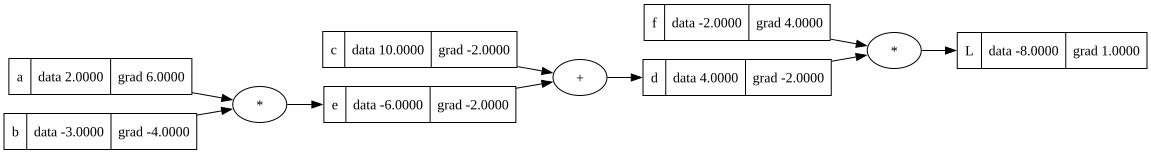

In [5]:
# Definimos la red / expresión matemática con etiquetas
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a * b
e.label = 'e'
d = e + c
d.label = 'd'
f = Value(-2.0, label='f')
L = d * f
L.label = 'L'

# Ejecutamos el backward pass
L.backward()

# Visualizamos el diagrama
draw_dot(L)

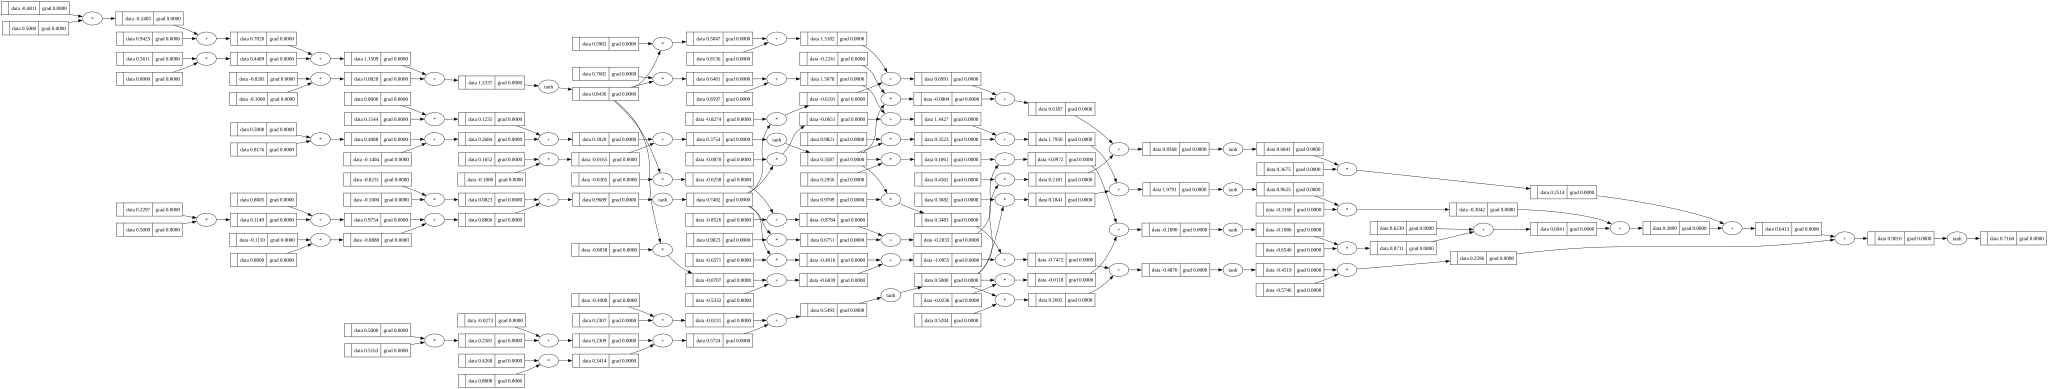

In [6]:
import random

# La clase Neuron representa el funcionamiento real de una neurona: Nin que es el número de inputs hace que w tenga que ser de su mismo tamaño pudiendo ser 2,3,4, etc los que sean. 
# Pero necesario que sea uno a uno porque para cada entrada hay un peso. Por otro lado también tenemos el bias que es uno solo por neurona y se suma al sumatorio de las entradas por los pesos.
class Neuron:
    def __init__(self, nin):
        """nin -> Number of inputs in the neuron so that you can create an equal amount of weights"""
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))            

    # Lo que quieres que pase cuando llamas a __call__ es el resultado de la neurona y x (lista de tamaño nin) es la entrada.
    # Con el zip multiplicamos cada peso con su correspondiente entrada 
    def __call__(self, x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

# Por otro lado la clase Layer, representa una capa de neuronas(Neuron). En este caso el numero de salidas es el número de neuronas en la capa oculta.
# Por lo tanto en el init lo que creamos es una lista de neuronas del número de salidas que buscamos con un número de inputs(entrada necesaria para crear Neuron).
class Layer:
    def __init__(self, nin, nout):
        """nout -> número de outputs significa número de salidas"""
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [neuron(x) for neuron in self.neurons]
        return outs[0] if len(outs) == 1 else outs

# Por último creamos lo que sería el multilayer perceptron. Es decir varias entradas a neuronas(Neuron) varias capas ocultas(Layer).
# Y finalmente se hace que solo devuelva una respuesta.
# Por otro lado nout(número de outputs realmente es el número de neuronas en la capa pero el output final es siempre 1).
class MLP:
    def __init__(self, nin, nouts):
        """nlay -> indica el número de capas ocultas""" 
        # Unimos ambos en una lista porq nouts es una lista ya. Esto se hace porque las entradas de la salida de la anterior nlayer son las entradas de la siguiente
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x


x = [0.5, 0.8, -0.1]
n = MLP(3, [4,4,1])
draw_dot(n(x))
